<a href="https://colab.research.google.com/github/Lepak121/Ind/blob/main/lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Завдання 1: K-Means (Фрукти) ===
Оптимальна кількість кластерів: k = 3
Коефіцієнт силуету для k=3: 0.8248
Координати центроїдів:
[[299.03986683   3.08017131]
 [507.90906528   5.51088444]
 [147.96486554   1.48559652]]



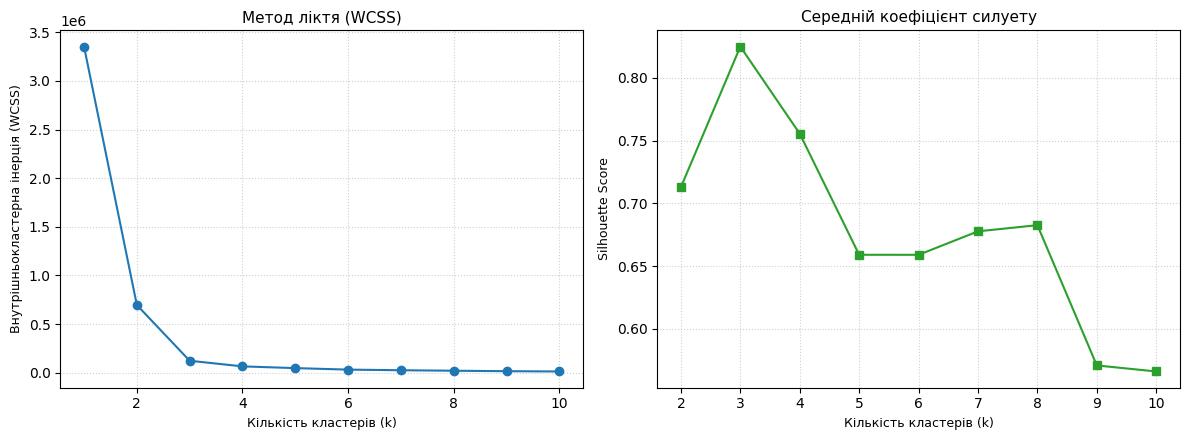

=== Завдання 2: Ієрархічна кластеризація (stocks.csv) ===
Розмірність матриці котирувань: (50, 6)



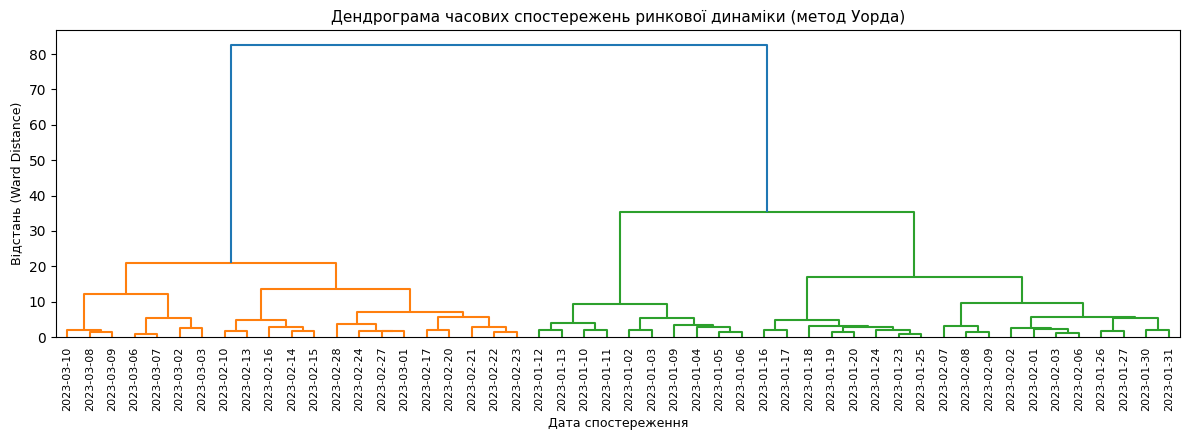

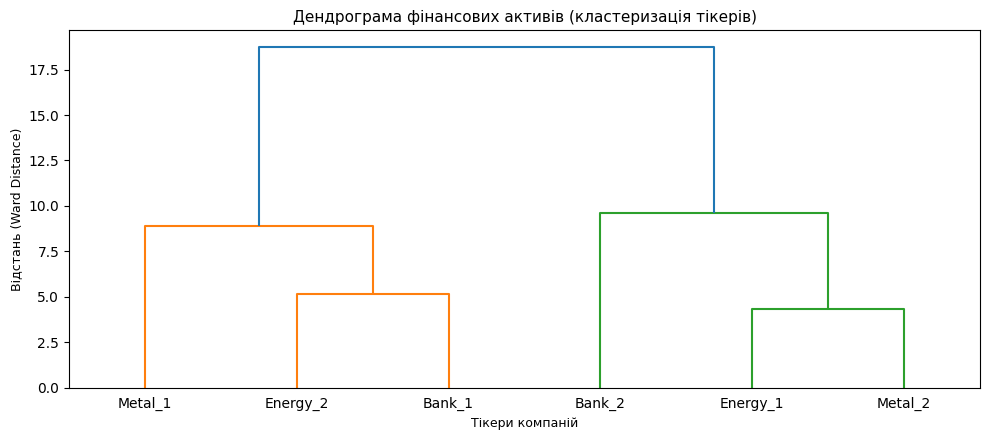

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage

# ==========================================
# ЗАВДАННЯ 1: КЛАСТЕРИЗАЦІЯ К-СЕРЕДНІХ (ФРУКТИ)
# ==========================================

# 1. Генерація або завантаження вибірки характеристик фруктів (вага, ціна)
np.random.seed(42)
cluster1 = np.random.normal(loc=[150, 1.5], scale=[15, 0.2], size=(50, 2))
cluster2 = np.random.normal(loc=[300, 3.0], scale=[25, 0.3], size=(50, 2))
cluster3 = np.random.normal(loc=[500, 5.5], scale=[40, 0.5], size=(50, 2))
X_fruits = np.vstack([cluster1, cluster2, cluster3])

# 2. Навчання KMeans з параметром n_clusters=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_fruits)
y_kmeans = kmeans.predict(X_fruits)

# 3. Розрахунок WCSS та Silhouette Score для діапазону k від 1 до 10
wcss = []
silhouette_scores = []
K_range = range(1, 11)

for k in K_range:
    if k == 1:
        kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans_temp.fit(X_fruits)
        wcss.append(kmeans_temp.inertia_)
        silhouette_scores.append(0)
    else:
        kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans_temp.fit_predict(X_fruits)
        wcss.append(kmeans_temp.inertia_)
        silhouette_scores.append(silhouette_score(X_fruits, labels))

print("=== Завдання 1: K-Means (Фрукти) ===")
print(f"Оптимальна кількість кластерів: k = 3")
print(f"Коефіцієнт силуету для k=3: {silhouette_scores[2]:.4f}")
print(f"Координати центроїдів:\n{kmeans.cluster_centers_}\n")

# Графіки для Завдання 1 (Лікоть та Силует)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)

axes[0].plot(K_range, wcss, marker='o', color='#1f77b4')
axes[0].set_title('Метод ліктя (WCSS)', fontsize=11)
axes[0].set_xlabel('Кількість кластерів (k)', fontsize=9)
axes[0].set_ylabel('Внутрішньокластерна інерція (WCSS)', fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(range(2, 11), silhouette_scores[1:], marker='s', color='#2ca02c')
axes[1].set_title('Середній коефіцієнт силуету', fontsize=11)
axes[1].set_xlabel('Кількість кластерів (k)', fontsize=9)
axes[1].set_ylabel('Silhouette Score', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


# ==========================================
# ЗАВДАННЯ 2: ІЄРАРХІЧНА КЛАСТЕРИЗАЦІЯ (STOCKS.CSV)
# ==========================================

# Генерація демонстраційного DataFrame для stocks.csv (замініть на pd.read_csv('stocks.csv', index_col=0) якщо є файл)
np.random.seed(42)
dates = pd.date_range(start='2023-01-01', periods=50, freq='B')
tickers = ['Energy_1', 'Energy_2', 'Bank_1', 'Bank_2', 'Metal_1', 'Metal_2']
stock_data = pd.DataFrame(np.random.randn(50, len(tickers)).cumsum(axis=0) + 100, index=dates, columns=tickers)

print("=== Завдання 2: Ієрархічна кластеризація (stocks.csv) ===")
print(f"Розмірність матриці котирувань: {stock_data.shape}\n")

# А. Кластеризація перших 50 часових спостережень
plt.figure(figsize=(12, 4.5), dpi=100)
mergings_time = linkage(stock_data.head(50), method='ward', metric='euclidean')
sch.dendrogram(mergings_time, labels=stock_data.head(50).index.strftime('%Y-%m-%d').tolist(), leaf_rotation=90, leaf_font_size=8)
plt.title('Дендрограма часових спостережень ринкової динаміки (метод Уорда)', fontsize=11)
plt.xlabel('Дата спостереження', fontsize=9)
plt.ylabel('Відстань (Ward Distance)', fontsize=9)
plt.tight_layout()
plt.show()

# Б. Кластеризація самих компаній (тікерів) зі стандартизацією
scaler = StandardScaler()
scaled_stocks = scaler.fit_transform(stock_data)
scaled_stocks_transposed = scaled_stocks.T

plt.figure(figsize=(10, 4.5), dpi=100)
mergings_tickers = linkage(scaled_stocks_transposed, method='ward', metric='euclidean')
sch.dendrogram(mergings_tickers, labels=stock_data.columns.tolist(), leaf_rotation=0, leaf_font_size=10)
plt.title('Дендрограма фінансових активів (кластеризація тікерів)', fontsize=11)
plt.xlabel('Тікери компаній', fontsize=9)
plt.ylabel('Відстань (Ward Distance)', fontsize=9)
plt.tight_layout()
plt.show()